<a href="https://colab.research.google.com/github/iarapineda/Ciencia-y-anal-tica-de-datos-Sep2026/blob/main/Actividad5Preprocesamiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: IARA PÉREZ PINEDA

*   MATRÍCULA: A01705855

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [3]:

cardio_df = pd.read_csv('heart_disease.csv', index_col='id')

cardio_df.info()

cardio_df.nunique()


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


El conjunto de datos contiene 918 registros y 15 variables, sin contar el identificador id, que se estableció como índice.
Se identificaron 7 columnas numéricas y 8 columnas de tipo texto (object). El análisis de valores únicos permite identificar variables que podrían representar categorías codificadas numéricamente, las cuales se revisarán en el ejercicio 2.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [4]:

cardio_df['ca'] = pd.Categorical(
    cardio_df['ca'], categories=[0, 1, 2, 3], ordered=True
)

cardio_df['num'] = pd.Categorical(
    cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True
)

cardio_df[['ca', 'num']].dtypes


,0
ca,category
num,category


Se identificaron dos variables numéricas con pocos valores únicos: `ca` (4 valores) y `num` (5 valores).

Ambas se convirtieron a variables categóricas ordinales, ya que representan valores con un orden definido. Para `ca` se estableció el orden de 0 a 3 y para `num` de 0 a 4.

Las demás variables conservaron sus tipos de datos originales.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [6]:

numericas = cardio_df.select_dtypes(include='number')
categoricas = cardio_df.select_dtypes(include=['object', 'category'])

#Numéricas
estadisticas_num = numericas.describe().T
estadisticas_num['sesgo'] = numericas.skew()
estadisticas_num['curtosis'] = numericas.kurt()

display(estadisticas_num)

#Categóricas
display(categoricas.describe().T)

for columna in categoricas.columns:
    print(f'Frecuencias de {columna}:')
    display(categoricas[columna].value_counts(dropna=False))


,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


Frecuencias de sex:


,count
sex,
Male,724
Female,194


Frecuencias de origin:


...

,count
ca,
NaN,609
0,181
1,67
2,41
3,20


Frecuencias de thal:


,count
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46


Frecuencias de num:


,count
num,
0,411
1,263
2,109
3,107
4,28


**Análisis de estadísticas descriptivas**

Las variables numéricas presentan diferentes distribuciones. Destaca `chol`, con sesgo positivo (1.64) y curtosis elevada (6.57), lo que sugiere posibles valores extremos. `oldpeak` también presenta asimetría positiva (1.04), mientras que `age` y `thalch` tienen distribuciones aproximadamente simétricas.

En las variables categóricas predominan los pacientes masculinos (724), el dolor torácico asintomático (495) y los pacientes sin enfermedad cardíaca registrada (411).

También se identificaron valores faltantes en distintas variables, especialmente `ca`, `thal` y `slope`, que se analizarán en el siguiente ejercicio.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [7]:

faltantes = cardio_df.isna().mean() * 100
display(faltantes.round(2))


,0
age,0.00
sex,0.00
origin,0.00
cp,0.00
trestbps,6.43
chol,3.27
fbs,9.69
restecg,0.00
thalch,5.99
exang,5.99


In [8]:

columnas_eliminar = faltantes[faltantes > 30].index

cardio_df = cardio_df.drop(columns=columnas_eliminar)

print("Columnas eliminadas:", list(columnas_eliminar))


Columnas eliminadas: ['slope', 'ca', 'thal']


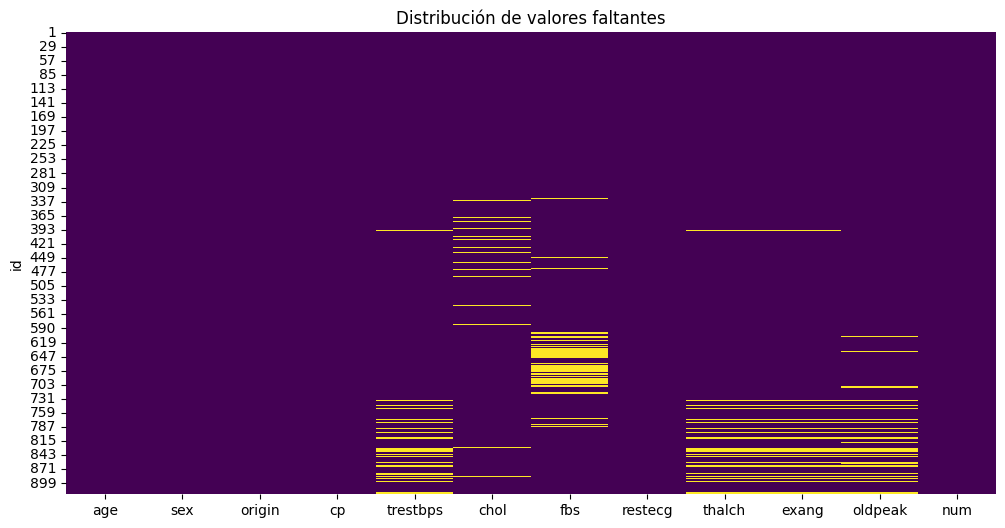

In [9]:

plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis')
plt.title('Distribución de valores faltantes')
plt.show()


**Análisis**

Se eliminaron las columnas `ca` (66.34%), `thal` (52.72%) y `slope` (33.55%), debido a que superaban el 30% de valores faltantes.

El mapa de calor permitió identificar faltantes simultáneos en `trestbps`, `thalch`, `exang` y `oldpeak`. Destaca la coincidencia completa de los 55 registros faltantes de `thalch` y `exang`.

Desde el punto de vista clínico esta concurrencia tiene sentido ya que varias de estas variables están relacionadas con la evaluación cardiovascular y las pruebas de esfuerzo. La ausencia simultánea podría deberse a pruebas no realizadas o registros incompletos, aunque no es posible confirmar la causa únicamente con los datos disponibles.

**Referencia de apoyo:** American Heart Association (2025). [Exercise Stress Test](https://www.heart.org/en/health-topics/heart-attack/diagnosing-a-heart-attack/exercise-stress-test).

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [10]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim(*att_range)
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [11]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

Análisis de age


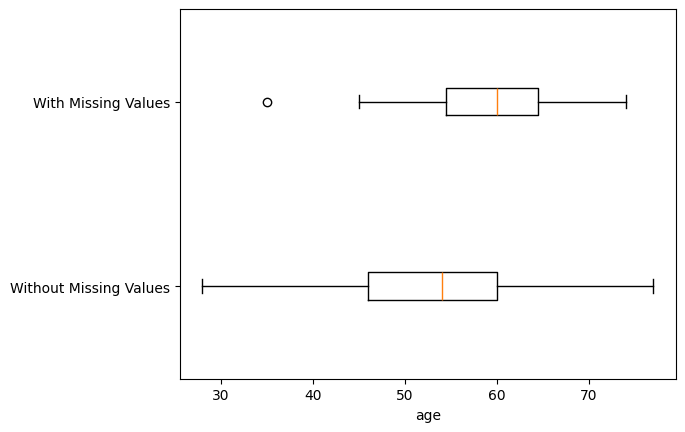

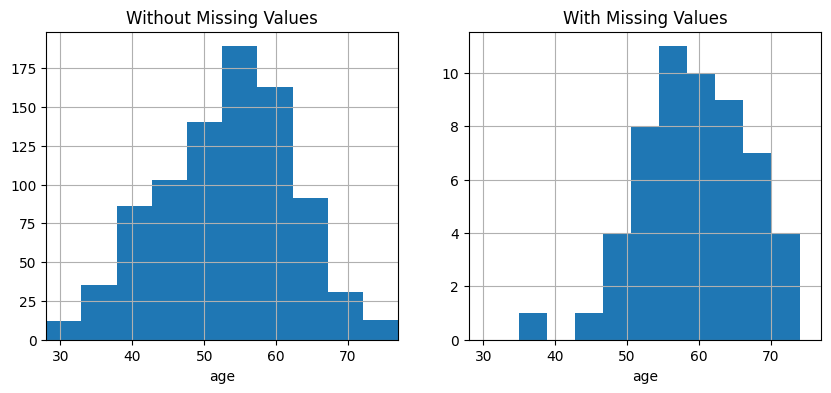

p-value of t-test: 1.5041244185890902e-06
Análisis de chol


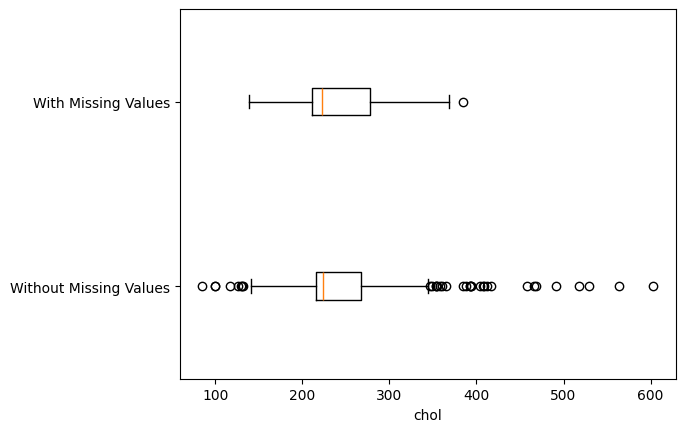

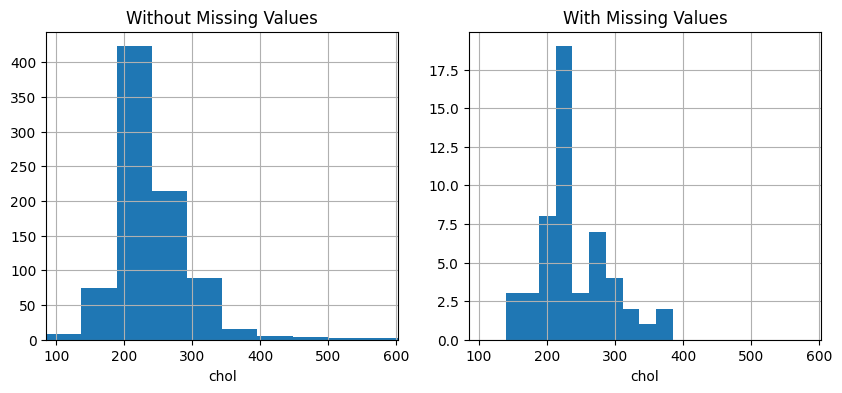

p-value of t-test: 0.7165289974295672
Análisis de restecg


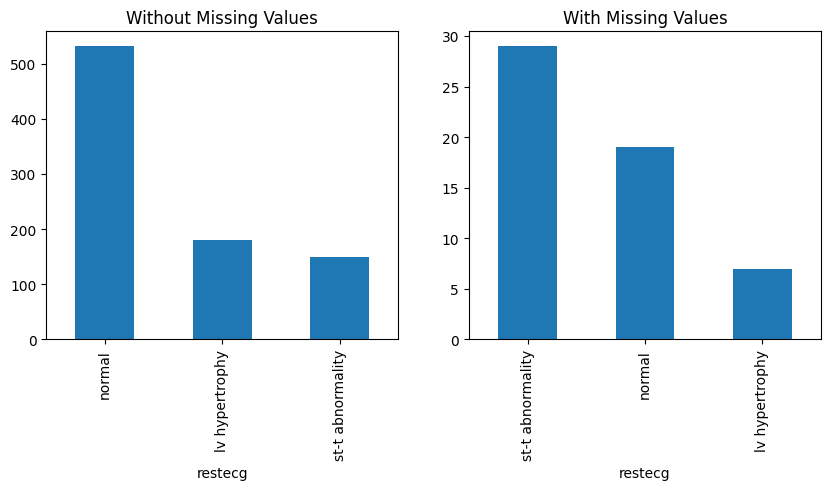

p-value of Chi_squared test: 1.1472889573985467e-09
Análisis de cp


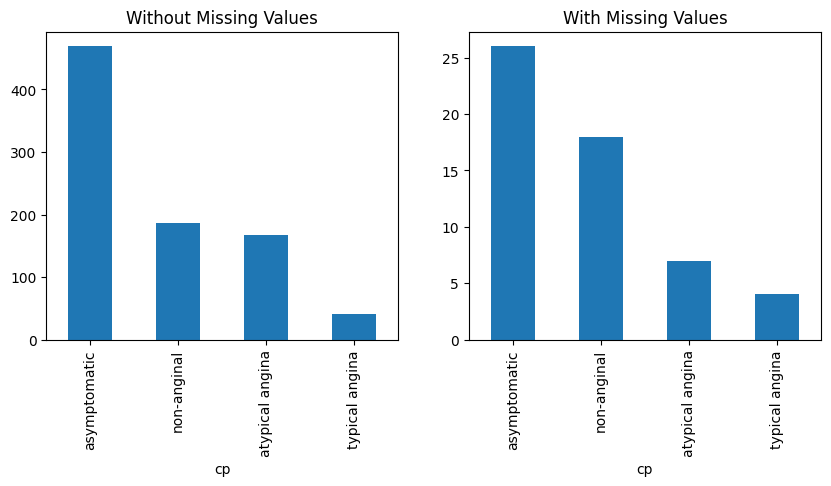

p-value of Chi_squared test: 0.15420097177251701


In [12]:
BM_MV = cardio_df['thalch'].isna()

#Numéricas
for variable in ['age', 'chol']:
    print(f'Análisis de {variable}')
    Diagnose_MV_Numerical(cardio_df, variable, BM_MV)

#Categóricas
for variable in ['restecg', 'cp']:
    print(f'Análisis de {variable}')
    Diagnose_MV_Categorical(cardio_df, variable, BM_MV)


**Análisis**

Se analizaron los valores faltantes de `thalch` mediante pruebas t para las variables numéricas (`age` y `chol`) y pruebas chi-cuadrada para las categóricas (`restecg` y `cp`), considerando un nivel de significancia de 0.05.

Los resultados mostraron diferencias estadísticamente significativas para `age` (p < 0.001) y `restecg` (p < 0.001). En cambio, `chol` (p = 0.717) y `cp` (p = 0.154) no presentaron asociaciones significativas.

Estos hallazgos indican que la ausencia de valores en `thalch` está relacionada con variables observadas, especialmente la edad y los resultados del electrocardiograma.

**En conclusión:** Las pruebas estadísticas identificaron asociaciones significativas entre los valores faltantes de thalch y las variables age y restecg (p < 0.05). En cambio, chol y cp no mostraron asociaciones significativas.

Los resultados permiten rechazar el supuesto de ausencia completamente aleatoria (MCAR) y sugieren un mecanismo MAR (Missing At Random), ya que los faltantes están relacionados con otras variables observadas. Sin embargo, las pruebas no permiten descartar completamente un mecanismo MNAR.


6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

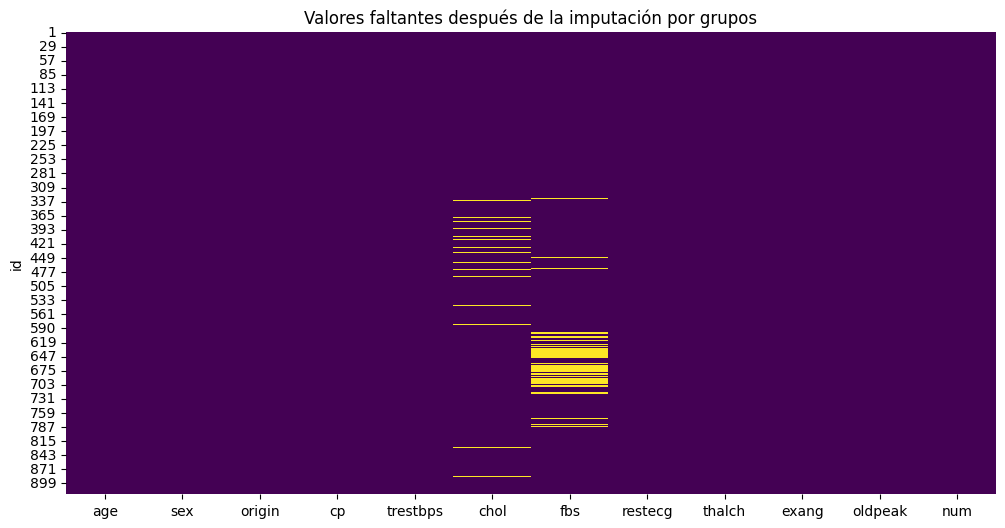

In [13]:

for columna in ['thalch', 'trestbps', 'oldpeak']:
    cardio_df[columna] = cardio_df.groupby('restecg')[columna].transform(
        lambda x: x.fillna(x.median())
    )

cardio_df['exang'] = cardio_df['exang'].astype('boolean')
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(
    lambda x: x.fillna(x.mode().iloc[0])
)

plt.figure(figsize=(12, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap='viridis')
plt.title('Valores faltantes después de la imputación por grupos')
plt.show()


**Análisis de imputación**

Se imputaron los valores faltantes de `thalch`, `trestbps`, `oldpeak` y `exang`, utilizando `restecg` como variable de agrupación.

Para las variables numéricas se utilizó la mediana de cada grupo, debido a su menor sensibilidad a valores extremos. Para `exang`, al ser categórica, se utilizó la moda.

El mapa de calor final permite verificar que estas cuatro variables ya no presentan valores faltantes. Permanecen valores ausentes en `chol` y `fbs`, que serán tratados en el siguiente ejercicio.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [14]:

from sklearn.impute import SimpleImputer

cardio_df[['chol']] = SimpleImputer(strategy='median').fit_transform(cardio_df[['chol']])

cardio_df[['fbs']] = SimpleImputer(strategy='most_frequent').fit_transform(cardio_df[['fbs']])

cardio_df.isna().sum()


,0
age,0
sex,0
origin,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


**Análisis imputación global**

Se imputaron los valores faltantes restantes mediante `SimpleImputer`, utilizando estadísticas generales de cada columna.

Para `chol` se empleó la mediana, debido a su distribución sesgada y a la posible presencia de valores extremos. Para `fbs` se utilizó la categoría más frecuente, ya que es una variable categórica.

Después de la imputación, se verificó que el conjunto de datos no presenta valores faltantes.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

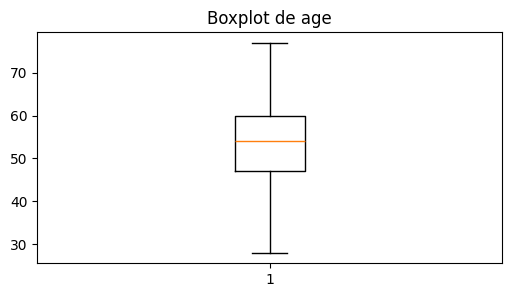

age: []


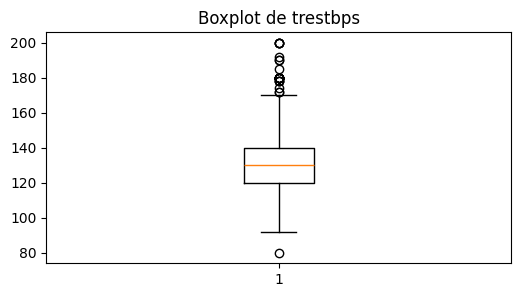

trestbps: [ 80. 172. 180. 200. 174. 178. 192. 180. 178. 180. 190. 180. 180. 180.
 180. 200. 180. 180. 180. 200. 185. 200. 180. 178. 172. 180. 190.]


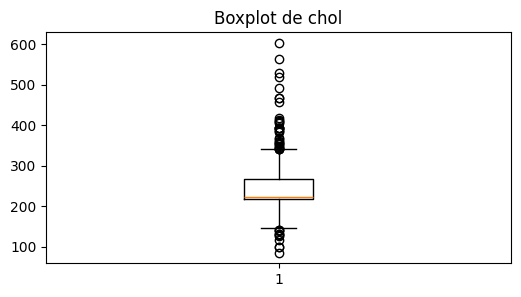

chol: [141. 126. 131. 132. 129. 100.  85. 117. 100. 142. 139. 354. 353. 417.
 360. 407. 564. 394. 409. 342. 358. 412. 468. 365. 344. 394. 347. 466.
 529. 392. 355. 603. 342. 404. 518. 388. 491. 342. 393. 458. 384. 349.
 369. 385.]


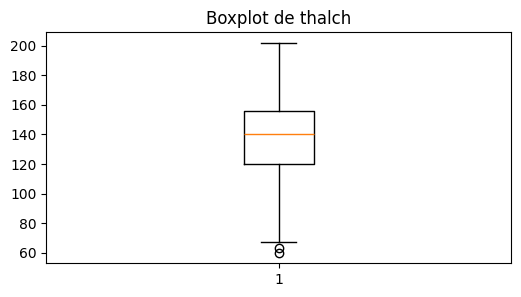

thalch: [60. 63.]


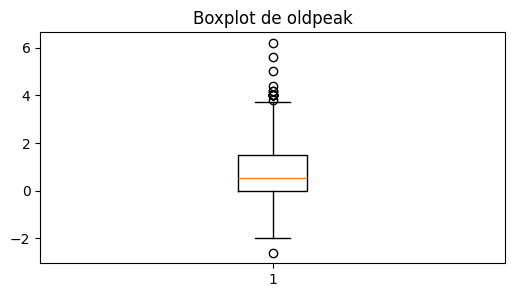

oldpeak: [-2.6  6.2  4.   5.6  4.   4.2  4.2  3.8  4.4  4.   4.   5.   4.   4.
  4.   4. ]


In [15]:

for columna in cardio_df.select_dtypes(include='number').columns:
    plt.figure(figsize=(6, 3))
    box = plt.boxplot(cardio_df[columna])
    plt.title(f'Boxplot de {columna}')
    plt.show()

    atipicos = box['fliers'][0].get_ydata()
    print(f'{columna}: {atipicos}')


**Análisis de valores atípicos**

Se generaron boxplots para las cinco variables numéricas y se identificaron los valores atípicos a partir de los puntos fuera de los bigotes.

La variable `age` no presentó valores atípicos, mientras que `trestbps`, `chol`, `thalch` y `oldpeak` registraron 27, 44, 2 y 16 observaciones atípicas, respectivamente.

La presencia de estos valores indica observaciones alejadas de la distribución central, aunque no necesariamente representa errores en los datos.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [16]:

Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

atipicos_iqr = cardio_df.loc[
    (cardio_df['trestbps'] < limite_inferior) |
    (cardio_df['trestbps'] > limite_superior),
    'trestbps'
]

print(f'Q1: {Q1}, Q3: {Q3}, IQR: {IQR}')
print(f'Límite inferior: {limite_inferior}')
print(f'Límite superior: {limite_superior}')
print(f'Cantidad de atípicos: {len(atipicos_iqr)}')
display(atipicos_iqr)


Q1: 120.0, Q3: 140.0, IQR: 20.0
Límite inferior: 90.0
Límite superior: 170.0
Cantidad de atípicos: 27


,trestbps
id,
15,172.0
84,180.0
127,200.0
173,174.0
184,178.0
189,192.0
202,180.0
214,178.0
232,180.0


**Análisis rango intercuartílico**

Para `trestbps` se obtuvieron Q1 = 120, Q3 = 140 e IQR = 20. Aplicando la regla de 1.5 × IQR, se establecieron los límites inferior y superior de 90 y 170 mm Hg, respectivamente.

Se identificaron 27 valores atípicos, coincidiendo con los resultados del boxplot de la pregunta 8.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

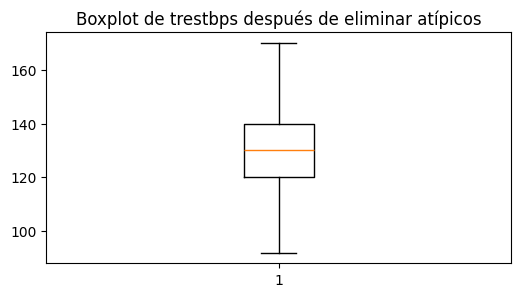

In [17]:

cardio_df = cardio_df.drop(index=atipicos_iqr.index)

plt.figure(figsize=(6, 3))
plt.boxplot(cardio_df['trestbps'])
plt.title('Boxplot de trestbps después de eliminar atípicos')
plt.show()


**Análisis eliminación de valores atípicos**

Se eliminaron las 27 observaciones identificadas como atípicas en `trestbps` mediante el método IQR, reduciendo el conjunto de datos de 918 a 891 registros.

Posteriormente, se generó un nuevo boxplot para visualizar la distribución de la presión arterial en reposo después de la depuración.

---

**Declaración de uso de IA**

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje grande]. https://chatgpt.com/

Usé chat como herramienta de apoyo para la generación y revisión de código en Python, y entendimiento de procesos y análisis.
---